# 03 – Model Development and Hyperparameter Tuning


Goal: In this notebook, we compare several models with our logistic regression baseline. We tune their hyperparameters, choose a decision threshold to reach 95% recall on phishing, and look at the errors. We only use the training set: the test set is kept for the final evaluation in week 4. All models are tested with 5-fold cross-validation and placed in a Pipeline to avoid data leakage.

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_recall_curve, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
X_train, y_train = train.drop(columns="class"), train["class"]
print("Train:", X_train.shape, "| phishing share:", round(y_train.mean(), 3))

Train: (4679, 30) | phishing share: 0.516


## 1. Models and hyperparameter grids
We test six models:
- Logistic regression: our baseline, with a tuned regularisation.
- Decision tree: simple and easy to interpret, but it can overfit.
- k-NN: classifies a website like its closest neighbours.
- SVM: finds a non-linear boundary between the two classes.
- Random Forest: combines many decision trees to reduce overfitting.
- Gradient Boosting: builds trees one after the other, each one correcting the errors of the previous ones.

For SVM and k-NN, the data is scaled inside the Pipeline. We keep small grids of hyperparameters so the notebook runs in a few minutes.

In [5]:
models = {
    "Logistic regression": (
        Pipeline([("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision tree": (
        Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
        {"clf__max_depth": [3, 5, 10, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "k-NN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 11, 21], "clf__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=SEED))]),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]}),
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        {"clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 3],
         "clf__max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (
        Pipeline([("clf", HistGradientBoostingClassifier(random_state=SEED))]),
        {"clf__learning_rate": [0.05, 0.1], "clf__max_iter": [200, 400],
         "clf__max_depth": [None, 6], "clf__l2_regularization": [0.0, 1.0]}),
}

## 2. Hyperparameter tuning with cross-validation
For each model, we test all combinations of hyperparameters with 5-fold cross-validation. We keep the best combination based on ROC-AUC, because this score does not depend on the decision threshold, which we choose later. We also look at the training score: if it is much higher than the cross-validation score, the model is overfitting.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"}

searches, rows = {}, {}
for name, (pipe, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit="roc_auc",
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    r = gs.cv_results_
    rows[name] = {
        "recall":    f"{r['mean_test_recall'][i]:.3f} ± {r['std_test_recall'][i]:.3f}",
        "precision": f"{r['mean_test_precision'][i]:.3f} ± {r['std_test_precision'][i]:.3f}",
        "f1":        f"{r['mean_test_f1'][i]:.3f} ± {r['std_test_f1'][i]:.3f}",
        "roc_auc":   f"{r['mean_test_roc_auc'][i]:.3f} ± {r['std_test_roc_auc'][i]:.3f}",
        "train_auc - cv_auc": round(r['mean_train_roc_auc'][i] - r['mean_test_roc_auc'][i], 3),
        "time (s)": round(time.time() - t0, 1),
    }
    print(f"{name:20s} best params: {gs.best_params_}")

results = pd.DataFrame(rows).T
results

Logistic regression  best params: {'clf__C': 10}
Decision tree        best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 20}
k-NN                 best params: {'clf__n_neighbors': 11, 'clf__weights': 'uniform'}
SVM (RBF)            best params: {'clf__C': 10, 'clf__gamma': 'scale'}
Random Forest        best params: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}
Gradient Boosting    best params: {'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__max_iter': 200}


,recall,precision,f1,roc_auc,train_auc - cv_auc,time (s)
Logistic regression,0.918 ± 0.007,0.928 ± 0.010,0.923 ± 0.003,0.976 ± 0.002,0.002,14.0
Decision tree,0.912 ± 0.014,0.937 ± 0.013,0.924 ± 0.002,0.977 ± 0.004,0.009,2.0
k-NN,0.933 ± 0.006,0.909 ± 0.008,0.921 ± 0.004,0.975 ± 0.003,0.012,6.2
SVM (RBF),0.945 ± 0.007,0.950 ± 0.015,0.947 ± 0.007,0.986 ± 0.002,0.011,44.2
Random Forest,0.934 ± 0.008,0.960 ± 0.010,0.946 ± 0.004,0.989 ± 0.002,0.006,46.4
Gradient Boosting,0.948 ± 0.003,0.955 ± 0.012,0.951 ± 0.005,0.993 ± 0.001,0.007,45.9


Note: these scores are a bit optimistic, because we use the same folds to choose the hyperparameters and to measure the score. The real score will come from the test set in week 4.

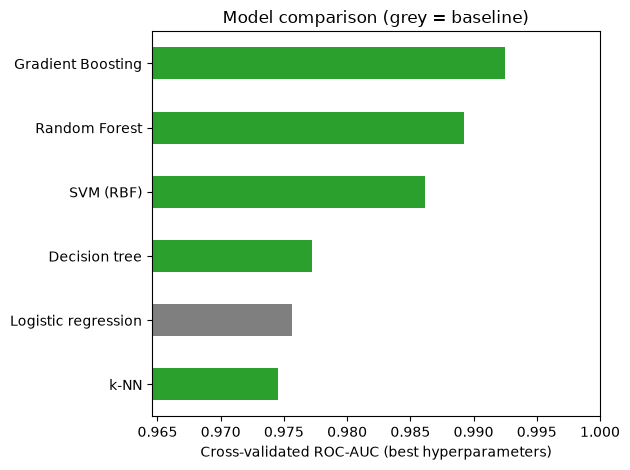

In [7]:
auc = pd.Series({n: s.best_score_ for n, s in searches.items()}).sort_values()
ax = auc.plot.barh(color=["tab:gray" if n == "Logistic regression" else "tab:green" for n in auc.index])
ax.set_xlim(auc.min() - 0.01, 1.0)
ax.set_xlabel("Cross-validated ROC-AUC (best hyperparameters)")
ax.set_title("Model comparison (grey = baseline)")
plt.tight_layout(); plt.savefig(FIG_DIR / "models_roc_auc.png", dpi=150); plt.show()

## 3. Overfitting check
Here we compare the score on the training data with the cross-validation score. If the gap is large, the model learns the training data by heart and will not work well on new websites.

In [8]:
gap = results["train_auc - cv_auc"].astype(float).sort_values()
print(gap)

Logistic regression    0.002
Random Forest          0.006
Gradient Boosting      0.007
Decision tree          0.009
SVM (RBF)              0.011
k-NN                   0.012
Name: train_auc - cv_auc, dtype: float64


## 4. Decision threshold for the recall target
By default, a model predicts phishing when the probability is above 0.5. To reach 95% recall, we can lower this threshold. To choose it without using the test set, each website gets a probability from a model that did not see it during training. We then keep the threshold with the best precision among those that reach 95% recall. We do this for the best model and for the baseline, so we can compare them at the same recall.

Best model: Gradient Boosting
Gradient Boosting    threshold = 0.516 | recall = 0.950 | precision = 0.953 | F1 = 0.951
Logistic regression  threshold = 0.294 | recall = 0.950 | precision = 0.876 | F1 = 0.912


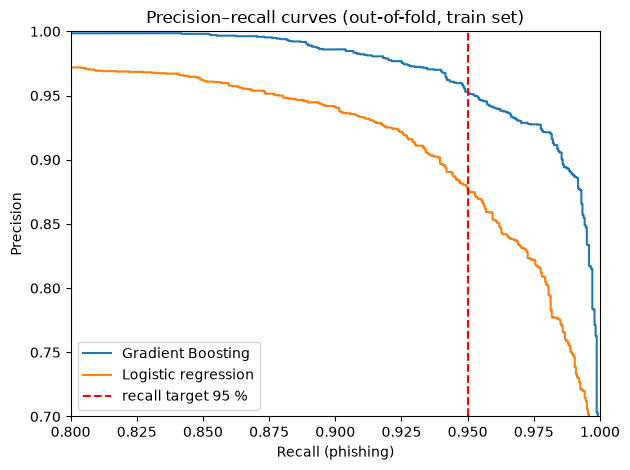

In [9]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
print("Best model:", best_name)

cv_thr = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)   # different folds than tuning

def pick_threshold(estimator, target_recall=0.95):
    proba = cross_val_predict(estimator, X_train, y_train, cv=cv_thr, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, proba)
    prec, rec = prec[:-1], rec[:-1]               # last point has no threshold
    ok = rec >= target_recall
    best = np.argmax(np.where(ok, prec, -1))
    return proba, thr[best], prec, rec, thr

thresholds = {}
for name in [best_name, "Logistic regression"]:
    proba, t, prec, rec, thr = pick_threshold(searches[name].best_estimator_)
    y_hat = (proba >= t).astype(int)
    thresholds[name] = {"proba": proba, "threshold": t}
    print(f"{name:20s} threshold = {t:.3f} | recall = {recall_score(y_train, y_hat):.3f} "
          f"| precision = {precision_score(y_train, y_hat):.3f} | F1 = {f1_score(y_train, y_hat):.3f}")
    plt.plot(rec, prec, label=name)

plt.axvline(0.95, ls="--", color="red", label="recall target 95 %")
plt.xlabel("Recall (phishing)"); plt.ylabel("Precision"); plt.xlim(0.8, 1.0); plt.ylim(0.7, 1.0)
plt.title("Precision–recall curves (out-of-fold, train set)"); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "precision_recall_threshold.png", dpi=150); plt.show()

## 5. Error analysis of the best model
We show the confusion matrix with the chosen threshold, then we look at the phishing websites the model missed.

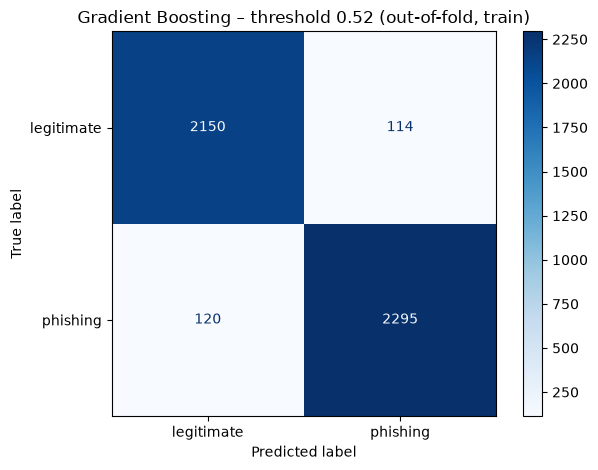

Missed phishing (FN): 120 | False alarms (FP): 114


In [10]:
proba = thresholds[best_name]["proba"]
t = thresholds[best_name]["threshold"]
y_hat = (proba >= t).astype(int)

cm = confusion_matrix(y_train, y_hat)
ConfusionMatrixDisplay(cm, display_labels=["legitimate", "phishing"]).plot(cmap="Blues")
plt.title(f"{best_name} – threshold {t:.2f} (out-of-fold, train)")
plt.tight_layout(); plt.savefig(FIG_DIR / "best_model_confusion_matrix.png", dpi=150); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Missed phishing (FN): {fn} | False alarms (FP): {fp}")

In [11]:
fn_mask = (y_train == 1) & (y_hat == 0)
tp_mask = (y_train == 1) & (y_hat == 1)
compare = pd.DataFrame({
    "missed phishing (FN)": X_train[fn_mask].mean(),
    "detected phishing (TP)": X_train[tp_mask].mean(),
})
compare["difference"] = compare.iloc[:, 0] - compare.iloc[:, 1]
compare.sort_values("difference", key=abs, ascending=False).head(8).round(2)

,missed phishing (FN),detected phishing (TP),difference
HTTPS,0.42,-0.53,0.95
AnchorURL,0.09,-0.65,0.74
RequestURL,0.37,-0.15,0.51
WebsiteTraffic,0.42,-0.01,0.42
SubDomains,0.16,-0.18,0.34
InfoEmail,0.78,0.58,0.20
StatsReport,0.82,0.62,0.20
GoogleIndex,0.77,0.57,0.20


The missed phishing websites have higher values on some features, like HTTPS or AnchorURL. This means they show signs of a legitimate website, so the model cannot tell them apart. This is a limit of our dataset.

## Conclusions
- All models are compared with the same folds and metrics as the baseline.
- Gradient Boosting is the best model (ROC-AUC 0.993 vs 0.976 for the baseline), followed by Random Forest and SVM. These models can combine several features, which a linear model cannot do.
- No model overfits much: the gap between training and cross-validation scores stays around 0.01.
- At 95% recall, Gradient Boosting has a precision of 0.95, against 0.88 for the baseline, so it gives far fewer false alarms.
- The missed phishing websites look legitimate on HTTPS and AnchorURL, our two most important features. This is a limit of the dataset.
- We have not used the test set yet. In week 4, we will retrain the best model on the whole training set and test it once on the test set.